# Credit Card Delinquency Risk: EDA and Baseline Modeling

**Context:** Tata iQ GenAI Powered Data Analytics Job Simulation (Forage). Geldium Finance, a fictional consumer lender, wants to identify customers at risk of missing credit card payments.

**This notebook covers:**
1. Dataset structure and target balance
2. Data quality audit (missing values, inconsistent labels, logical conflicts)
3. Missingness diagnosis (MCAR / MAR) and imputation
4. Risk factor analysis and customer segments
5. Baseline predictive models with cross-validation
6. Fairness snapshot

> **Data:** the dataset belongs to the Forage simulation and is not included in this repository. To run the notebook, enroll in the simulation, download `Delinquency_prediction_dataset.xlsx`, and place it in the `data/` folder.

## 1. Setup and data loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from pathlib import Path

# Works whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "Delinquency_prediction_dataset.xlsx"
IMG_DIR = ROOT / "images"
IMG_DIR.mkdir(exist_ok=True)

df = pd.read_excel(DATA_PATH)
MONTHS = [f"Month_{i}" for i in range(1, 7)]
print(df.shape)
df.head()

(500, 19)


,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,Account_Tenure,Credit_Card_Type,Location,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6
0,CUST0001,56,165580.0,398.0,0.390502,3,0,16310.0,0.317396,EMP,18,Student,Los Angeles,Late,Late,Missed,Late,Missed,Late
1,CUST0002,69,100999.0,493.0,0.312444,6,1,17401.0,0.196093,Self-employed,0,Standard,Phoenix,Missed,Missed,Late,Missed,On-time,On-time
2,CUST0003,46,188416.0,500.0,0.359930,0,0,13761.0,0.301655,Self-employed,1,Platinum,Chicago,Missed,Late,Late,On-time,Missed,Late
3,CUST0004,32,101672.0,413.0,0.371400,3,0,88778.0,0.264794,Unemployed,15,Platinum,Phoenix,Late,Missed,Late,Missed,Late,Late
4,CUST0005,60,38524.0,487.0,0.234716,2,0,13316.0,0.510583,Self-employed,11,Standard,Phoenix,Missed,On-time,Missed,Late,Late,Late


## 2. Dataset structure and target balance

In [2]:
df.dtypes.value_counts()

str        10
float64     5
int64       4
Name: count, dtype: int64

In [3]:
target = df["Delinquent_Account"]
print(target.value_counts())
print(f"Delinquency rate: {target.mean():.1%}")

Delinquent_Account
0    420
1     80
Name: count, dtype: int64
Delinquency rate: 16.0%


The target is **imbalanced**: only 16% of customers are delinquent. A model that predicts "not delinquent" for everyone would already be 84% accurate, so accuracy is not a useful metric here. Recall, precision, F1 and AUC are used instead.

## 3. Data quality audit

### 3.1 Missing values and duplicates

In [4]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(1)
print(missing)
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate Customer_IDs:", df["Customer_ID"].duplicated().sum())

              missing  pct
Income             39  7.8
Credit_Score        2  0.4
Loan_Balance       29  5.8
Duplicate rows: 0 | Duplicate Customer_IDs: 0


### 3.2 Inconsistent category labels

In [5]:
df["Employment_Status"].value_counts()

Employment_Status
Unemployed       93
retired          87
Employed         82
EMP              81
Self-employed    80
employed         77
Name: count, dtype: int64

"Employed", "employed" and "EMP" describe the same group. `Credit_Card_Type` also contains "Student" and "Business", which are not listed in the dataset guide.

In [6]:
df["Credit_Card_Type"].value_counts()

Credit_Card_Type
Gold        118
Student     112
Business    108
Standard     86
Platinum     76
Name: count, dtype: int64

### 3.3 Units, floor values and over-limit accounts

In [7]:
print("Credit_Utilization range:", df["Credit_Utilization"].min(), "to", round(df["Credit_Utilization"].max(), 3))
print("Debt_to_Income_Ratio range:", df["Debt_to_Income_Ratio"].min(), "to", round(df["Debt_to_Income_Ratio"].max(), 3))
print("Utilization > 1.0 (over limit):", (df["Credit_Utilization"] > 1).sum())
print("Utilization exactly 0.05:", (df["Credit_Utilization"] == 0.05).sum())
print("Debt-to-income exactly 0.10:", (df["Debt_to_Income_Ratio"] == 0.10).sum())

Credit_Utilization range: 0.05 to 1.026
Debt_to_Income_Ratio range: 0.1 to 0.553
Utilization > 1.0 (over limit): 4
Utilization exactly 0.05: 9
Debt-to-income exactly 0.10: 14


The guide describes both ratios as percentages (0–100%), but they are stored as decimals (0–1). The clusters at exactly 0.05 and 0.10 look like floor or default values rather than real observations.

### 3.4 Logical conflicts between fields

In [8]:
missed_6m = (df[MONTHS] == "Missed").sum(axis=1)
checks = {
    "Missed_Payments (12m) < missed months in last 6m": (df["Missed_Payments"] < missed_6m).sum(),
    "Credit score >= 750 with 4+ missed payments": ((df["Credit_Score"] >= 750) & (df["Missed_Payments"] >= 4)).sum(),
    "'retired' customers under 30": ((df["Employment_Status"] == "retired") & (df["Age"] < 30)).sum(),
    "Account tenure longer than adult years (Age - 18)": (df["Account_Tenure"] > df["Age"] - 18).sum(),
}
pd.Series(checks, name="records")

Missed_Payments (12m) < missed months in last 6m     141
Credit score >= 750 with 4+ missed payments           46
'retired' customers under 30                          14
Account tenure longer than adult years (Age - 18)     81
Name: records, dtype: int64

In [9]:
print("Spearman: Missed_Payments vs Credit_Score:", round(stats.spearmanr(df["Missed_Payments"], df["Credit_Score"], nan_policy="omit")[0], 3))
both = df.dropna(subset=["Income", "Loan_Balance"])
print("Spearman: Debt_to_Income_Ratio vs Loan_Balance / Income:", round(stats.spearmanr(both["Debt_to_Income_Ratio"], both["Loan_Balance"] / both["Income"])[0], 3))

Spearman: Missed_Payments vs Credit_Score: -0.012
Spearman: Debt_to_Income_Ratio vs Loan_Balance / Income: 0.078


**Key finding:** for 141 customers (28%), the 12-month missed-payment count is *lower* than the number of missed months in the last six months alone, which is impossible. Fields that should move together in real credit data (credit score vs missed payments, debt-to-income vs loan/income) are essentially unrelated. The payment-history fields need to be reconciled with the data owner before they can be trusted.

## 4. Missingness diagnosis and imputation

Before imputing, we test whether missing values are related to the target or to other variables:
- **MCAR** (missing completely at random): no relationship with anything, so simple imputation is safe.
- **MAR** (missing at random): related to other observed variables.
- **MNAR** (missing not at random): related to the missing value itself; cannot be confirmed from the data alone.

In [10]:
def missingness_report(col):
    m = df[col].isna()
    fisher_p = stats.fisher_exact(pd.crosstab(m, target).values)[1]
    rows = [("Delinquency rate", df.loc[m, "Delinquent_Account"].mean(), df.loc[~m, "Delinquent_Account"].mean(), fisher_p)]
    for v in ["Age", "Credit_Score", "Credit_Utilization", "Missed_Payments", "Debt_to_Income_Ratio"]:
        if v == col:
            continue
        a, b = df.loc[m, v].dropna(), df.loc[~m, v].dropna()
        rows.append((v, a.mean(), b.mean(), stats.mannwhitneyu(a, b).pvalue))
    return pd.DataFrame(rows, columns=["variable", "mean_if_missing", "mean_if_present", "p_value"]).round(3)

for col in ["Income", "Loan_Balance"]:
    print(f"\n{col} (missing n={df[col].isna().sum()})")
    print(missingness_report(col).to_string(index=False))


Income (missing n=39)
            variable  mean_if_missing  mean_if_present  p_value
    Delinquency rate            0.128            0.163    0.820
                 Age           47.974           46.121    0.524
        Credit_Score          596.474          576.167    0.439
  Credit_Utilization            0.529            0.488    0.230
     Missed_Payments            3.282            2.941    0.274
Debt_to_Income_Ratio            0.289            0.300    0.586

Loan_Balance (missing n=29)
            variable  mean_if_missing  mean_if_present  p_value
    Delinquency rate            0.241            0.155    0.292
                 Age           46.379           46.259    0.936
        Credit_Score          543.786          579.738    0.292
  Credit_Utilization            0.555            0.488    0.097
     Missed_Payments            2.966            2.968    0.987
Debt_to_Income_Ratio            0.248            0.302    0.006


- **Income:** no significant differences (all p > 0.2), consistent with **MCAR**.
- **Loan_Balance:** missingness is linked to a lower debt-to-income ratio (p = 0.006), so it is **MAR**. These customers also show a higher, though not significant, delinquency rate (24.1% vs 15.5%).

**Treatment:** median imputation plus a missing-value flag for Income and Loan_Balance, and median imputation for the two missing Credit_Score values. Deleting incomplete rows would drop 64 customers (12.8%), including 11 delinquent ones. Both distributions are close to symmetric, so the median is a safe, transparent choice.

In [11]:
print("Income mean vs median:", round(df["Income"].mean()), df["Income"].median())
print("Loan_Balance mean vs median:", round(df["Loan_Balance"].mean()), df["Loan_Balance"].median())
print("Rows with any missing value:", df[["Income", "Loan_Balance", "Credit_Score"]].isna().any(axis=1).sum())

Income mean vs median: 108380 107658.0
Loan_Balance mean vs median: 48654 45776.0
Rows with any missing value: 64


In [12]:
clean = df.copy()
clean["Employment_Status"] = clean["Employment_Status"].str.lower().replace({"emp": "employed"})
for col in ["Income", "Loan_Balance"]:
    clean[f"{col}_Missing"] = clean[col].isna().astype(int)
for col in ["Income", "Loan_Balance", "Credit_Score"]:
    clean[col] = clean[col].fillna(clean[col].median())
clean["Missed_Months_6m"] = (clean[MONTHS] == "Missed").sum(axis=1)
clean["Late_Months_6m"] = (clean[MONTHS] == "Late").sum(axis=1)
print(clean["Employment_Status"].value_counts())
print("Remaining missing values:", clean[["Income", "Loan_Balance", "Credit_Score"]].isna().sum().sum())

Employment_Status
employed         240
unemployed        93
retired           87
self-employed     80
Name: count, dtype: int64
Remaining missing values: 0


## 5. Risk factors and customer segments

### 5.1 Correlation with delinquency

In [13]:
num_cols = ["Age", "Income", "Credit_Score", "Credit_Utilization", "Missed_Payments",
            "Loan_Balance", "Debt_to_Income_Ratio", "Account_Tenure", "Missed_Months_6m", "Late_Months_6m"]
rows = []
for v in num_cols:
    r, p = stats.pointbiserialr(clean["Delinquent_Account"], clean[v])
    rows.append((v, round(r, 3), round(p, 3)))
pd.DataFrame(rows, columns=["variable", "r", "p_value"]).sort_values("r", key=abs, ascending=False)

,variable,r,p_value
1,Income,0.044,0.326
7,Account_Tenure,-0.040,0.374
2,Credit_Score,0.035,0.438
6,Debt_to_Income_Ratio,0.034,0.443
3,Credit_Utilization,0.034,0.445
4,Missed_Payments,-0.026,0.555
9,Late_Months_6m,-0.024,0.592
0,Age,0.023,0.616
5,Loan_Balance,-0.005,0.903
8,Missed_Months_6m,-0.001,0.976


In [14]:
for c in ["Employment_Status", "Credit_Card_Type", "Location"]:
    p = stats.chi2_contingency(pd.crosstab(clean[c], clean["Delinquent_Account"]))[1]
    print(f"{c}: chi-square p = {p:.2f}")

Employment_Status: chi-square p = 0.55
Credit_Card_Type: chi-square p = 0.35


Location: chi-square p = 0.66


No single variable has a statistically meaningful relationship with delinquency (all |r| < 0.05). This is unusual for credit data and reinforces the data-quality concern in Section 3.4.

### 5.2 Directional risk factors

In [15]:
y = clean["Delinquent_Account"]
factors = {
    "Debt-to-income > 20%": clean["Debt_to_Income_Ratio"] > 0.20,
    "Credit use > 30%": clean["Credit_Utilization"] > 0.30,
    "Account tenure <= 2 years": clean["Account_Tenure"] <= 2,
}
rows = []
for name, mask in factors.items():
    p = stats.fisher_exact(pd.crosstab(mask, y).values)[1]
    rows.append((name, mask.sum(), y[mask].mean(), y[~mask].mean(), p))
risk = pd.DataFrame(rows, columns=["factor", "customers", "rate_if_true", "rate_if_false", "p_value"])
risk[["rate_if_true", "rate_if_false"]] = (risk[["rate_if_true", "rate_if_false"]] * 100).round(1)
risk.round(3)

,factor,customers,rate_if_true,rate_if_false,p_value
0,Debt-to-income > 20%,418,17.2,9.8,0.101
1,Credit use > 30%,417,16.8,12.0,0.328
2,Account tenure <= 2 years,77,20.8,15.1,0.236


### 5.3 Highest-risk segment

In [16]:
dti = clean["Debt_to_Income_Ratio"] > 0.20
util = clean["Credit_Utilization"] > 0.30
new = clean["Account_Tenure"] <= 2
segments = {
    "All other customers": ~(dti & util),
    "All customers (average)": pd.Series(True, index=clean.index),
    "Debt-to-income > 20%\nand credit use > 30%": dti & util,
    "...and account open\n2 years or less": dti & util & new,
}
seg = pd.DataFrame({
    "customers": {k: m.sum() for k, m in segments.items()},
    "delinquent": {k: y[m].sum() for k, m in segments.items()},
    "rate_pct": {k: round(y[m].mean() * 100, 1) for k, m in segments.items()},
})
seg["share_of_all_delinquent_pct"] = (seg["delinquent"] / y.sum() * 100).round(1)
print("Fisher p (high debt & high credit use vs rest):", round(stats.fisher_exact(pd.crosstab(dti & util, y).values)[1], 3))
seg

Fisher p (high debt & high credit use vs rest): 0.048


,customers,delinquent,rate_pct,share_of_all_delinquent_pct
All other customers,154,17,11.0,21.2
All customers (average),500,80,16.0,100.0
Debt-to-income > 20%\nand credit use > 30%,346,63,18.2,78.8
...and account open\n2 years or less,54,13,24.1,16.2


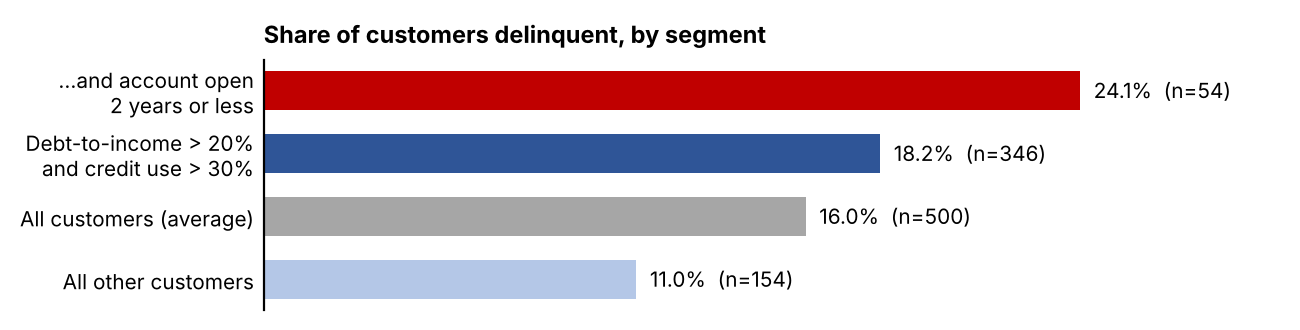

In [17]:
fig, ax = plt.subplots(figsize=(6.6, 1.75), dpi=200)
colors = ["#B4C7E7", "#A6A6A6", "#2F5597", "#C00000"]
bars = ax.barh(seg.index, seg["rate_pct"], color=colors, height=0.62)
for b, v, n in zip(bars, seg["rate_pct"], seg["customers"]):
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.1f}%  (n={n})", va="center", fontsize=7.5)
ax.set_xlim(0, 30)
ax.set_xticks([])
ax.tick_params(labelsize=7.5, length=0)
for s in ["top", "right", "bottom"]:
    ax.spines[s].set_visible(False)
ax.set_title("Share of customers delinquent, by segment", fontsize=8.5, loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(IMG_DIR / "segment_chart.png", facecolor="white")
plt.show()

Customers with both high debt-to-income and credit use above 30% account for **79% of all delinquent customers** (63 of 80), and this difference is borderline significant (p ≈ 0.05). However, the segment also covers about 70% of all customers, so it mainly filters out lower-risk customers rather than pinpointing a small high-risk group.

## 6. Baseline predictive models

Logistic regression (primary model: probability scores, transparent coefficients, stable on small data) and a shallow decision tree (benchmark). Age and Location are **excluded** as predictors and kept only for fairness checks. Evaluation uses stratified 5-fold cross-validation repeated 10 times, with class weighting for the 16% minority class.

In [18]:
X = pd.DataFrame({
    "Missed_Payments": clean["Missed_Payments"],
    "Missed_Months_6m": clean["Missed_Months_6m"],
    "Late_Months_6m": clean["Late_Months_6m"],
    "Debt_to_Income_Ratio": clean["Debt_to_Income_Ratio"],
    "Credit_Utilization": clean["Credit_Utilization"].clip(upper=1.0),
    "Over_Limit": (clean["Credit_Utilization"] > 1).astype(int),
    "Credit_Score": clean["Credit_Score"],
    "Account_Tenure": clean["Account_Tenure"],
    "Income": clean["Income"],
    "Income_Missing": clean["Income_Missing"],
    "Loan_Balance": clean["Loan_Balance"],
    "Loan_Balance_Missing": clean["Loan_Balance_Missing"],
})
X = pd.concat([X, pd.get_dummies(clean["Employment_Status"], prefix="Emp", drop_first=True).astype(int)], axis=1)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=1)
metrics = ["roc_auc", "average_precision", "recall", "precision", "f1", "accuracy"]
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight="balanced", random_state=0),
}
results = {}
for name, model in models.items():
    r = cross_validate(model, X, y, cv=cv, scoring=metrics)
    results[name] = {m: f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}" for m in metrics}
pd.DataFrame(results).T

,roc_auc,average_precision,recall,precision,f1,accuracy
Logistic regression,0.465 ± 0.045,0.172 ± 0.028,0.406 ± 0.099,0.140 ± 0.029,0.208 ± 0.044,0.508 ± 0.048
Decision tree (depth 3),0.485 ± 0.064,0.162 ± 0.016,0.644 ± 0.224,0.152 ± 0.032,0.243 ± 0.058,0.385 ± 0.103


**Interpretation:** both models score an AUC of roughly 0.47–0.49, which is no better than random guessing (0.50), and precision (about 0.14–0.15) is below the 0.16 base rate. The models do not meet the deployment criteria set in the plan (AUC ≥ 0.70, recall ≥ 0.70). The responsible conclusion is to **fix the data before deploying any model**, not to tune the model harder.

## 7. Fairness snapshot

In [19]:
age_band = pd.cut(clean["Age"], [17, 30, 45, 60, 75], labels=["18-30", "31-45", "46-60", "61-74"])
print("Delinquency rate by age band (%):")
print((y.groupby(age_band, observed=True).mean() * 100).round(1))
print("\nDelinquency rate by location (%):")
print((y.groupby(clean["Location"]).mean() * 100).round(1).sort_values())

Delinquency rate by age band (%):
Age
18-30    14.6
31-45    12.3
46-60    21.7
61-74    14.9
Name: Delinquent_Account, dtype: float64

Delinquency rate by location (%):
Location
New York       12.0
Chicago        14.6
Phoenix        16.5
Houston        16.8
Los Angeles    19.6
Name: Delinquent_Account, dtype: float64


Age and location show differences (e.g., 46–60 at 21.7%), but these are fragile once many comparisons are considered, and both can act as proxies for protected characteristics. They should be used only to **audit** model outcomes (disparate impact, equalized odds), never to decide how a customer is treated.

## 8. Conclusions

1. **Data quality is the main risk.** The data is largely complete (only three fields have gaps, all under 8%), but labels are inconsistent, units differ from the guide, and 28% of payment-history records contradict each other.
2. **Missing data** is handled with median imputation plus missing-value flags; Income is consistent with MCAR and Loan_Balance with MAR.
3. **Risk signals are weak.** High debt-to-income, high credit use and short tenure point in the expected direction, and the combined high-debt / high-credit-use segment holds 79% of delinquent customers.
4. **Baseline models perform at chance level**, so no model should drive customer decisions yet. The recommended next steps are to reconcile the data, then run a controlled outreach pilot with a comparison group to measure real impact.